# Tech Challenge — Fase 1
## Etapa 1 — Entendimento dos dados e primeiro modelo

O objetivo desta etapa é analisar os dados de clientes de uma operadora de telecomunicações e criar um modelo inicial para identificar possíveis cancelamentos de serviço (*churn*).

Usei a base IBM_Telco_customer_churn_IBM_dataset.csv, com 7.043 clientes e 33 colunas. Primeiro, descrevo o problema no ML Canvas. Depois, faço a análise exploratória, verifico os problemas encontrados na base e explico o que foi tratado ou retirado.

Com os dados preparados, treino uma **Regressão Logística** como modelo inicial (*baseline*) e avalio o resultado. Esse modelo servirá de referência para os outros modelos que serão testados na próxima etapa do trabalho.

## 1. Problema de negócio e ML Canvas

| Campo | Definição |
|---|---|
| **Problema de negócio** | A operadora precisa entender quais clientes têm maior risco de cancelar os serviços. |
| **Quem usaria o resultado** | Diretoria, equipe de retenção de clientes e equipe de dados. |
| **Objetivo** | Estimar a chance de cancelamento a partir das informações disponíveis sobre cada cliente. |
| **Como a previsão pode ajudar** | A equipe de retenção pode priorizar o contato com clientes de maior risco e avaliar ações como ofertas ou melhorias no atendimento. |
| **Tipo de problema** | Classificação binária: prever cancelamento (1) ou permanência (0). |
| **Unidade de análise** | Cada linha representa um cliente. |
| **Variável-alvo** | Churn Value: 1 para quem cancelou e 0 para quem permaneceu. |
| **Variáveis consideradas** | Tempo de relacionamento, contrato, serviços contratados e valores de cobrança. |
| **Primeiro modelo** | Regressão Logística com Scikit-Learn. |
| **Métricas técnicas** | F1-score e ROC-AUC como principais; também analiso precisão, recall, acurácia e matriz de confusão. |
| **Métrica de negócio** | Taxa de churn e percentual da cobrança mensal dos clientes que cancelaram e que foram identificados pelo modelo. |
| **Critério inicial de sucesso** | Identificar parte relevante dos cancelamentos e obter F1 superior à regra simples de sempre prever que o cliente ficará. |
| **Cuidados** | Evitar usar informações conhecidas apenas depois do cancelamento, tratar valores faltantes e observar os erros do modelo. |

Escolhi **F1-score** porque ele combina duas coisas importantes: quantos clientes sinalizados realmente cancelaram (*precisão*) e quantos dos que cancelaram foram encontrados (*recall*). A **ROC-AUC** ajuda a entender a capacidade do modelo de separar clientes com e sem churn, considerando diferentes limiares.

A métrica de negócio é uma aproximação: identificar um cliente que cancelou não significa que a operadora conseguiria impedir o cancelamento. Para medir isso de verdade, seria necessário testar ações de retenção.

## 2. Bibliotecas e configuração

Vou usar Pandas para trabalhar com a base, Matplotlib e Seaborn para os gráficos e Scikit-Learn para o modelo.

Defini a semente como **123** para conseguir repetir a mesma separação de clientes entre treino e teste. O número em si não tem nada de especial; o importante é mantê-lo fixo para comparar os experimentos.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

# Definição da semente para deixar a divisão aleatoria igual em novas execuções
SEMENTE = 123
np.random.seed(SEMENTE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

# Localizo a pasta principal do projeto.
caminhos = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]

RAIZ = next((p for p in caminhos if (p / "notebooks").is_dir()), Path.cwd())

DADOS = RAIZ / "data"
SAIDAS = RAIZ / "outputs"
MODELOS = RAIZ / "models"

# Crio as pastas para salvar os gráficos e o modelo, se necessário.
SAIDAS.mkdir(exist_ok=True, parents=True)
MODELOS.mkdir(exist_ok=True, parents=True)

print("Raiz do projeto:", RAIZ)
print("Versão do Scikit-Learn:", __import__("sklearn").__version__)

Raiz do projeto: c:\Users\Home\Documents\tech_challenge_fase_1
Versão do Scikit-Learn: 1.9.1


## 3. Carregando a base

A análise parte do CSV original, sem alterar o arquivo. Os ajustes são feitos em memória, em uma cópia dos dados. Assim, consigo voltar à base original caso precise conferir alguma informação.

In [2]:
ARQUIVO_CSV = DADOS / "IBM_Telco_customer_churn_IBM_dataset.csv"
if not ARQUIVO_CSV.exists():
    raise FileNotFoundError(f"Copie a planilha original para: {ARQUIVO_CSV}")

# Ler o CEP como texto, para não intepretar como numero, o valor não vai ser usado
df_original = pd.read_csv(ARQUIVO_CSV, dtype={"CustomerID": "string", "Zip Code": "string"})
origem = f"CSV recebido: {ARQUIVO_CSV.name}"
print("Fonte:", origem)
print("Dimensões originais:", df_original.shape)
display(df_original.head())

Fonte: CSV recebido: IBM_Telco_customer_churn_IBM_dataset.csv
Dimensões originais: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 4. Primeira verificação dos dados

Cada linha da planilha é um cliente. Quero prever a coluna Churn Value, em que 1 significa cancelamento e 0 significa que o cliente permaneceu.

Antes de pensar no modelo, vou conferir quantos registros existem, quais são as colunas, se há clientes repetidos e se aparecem campos vazios.

In [3]:
nomes_csv = {
    "customerID": "CustomerID", "gender": "Gender", "SeniorCitizen": "Senior Citizen",
    "tenure": "Tenure Months", "PhoneService": "Phone Service",
    "MultipleLines": "Multiple Lines", "InternetService": "Internet Service",
    "OnlineSecurity": "Online Security", "OnlineBackup": "Online Backup",
    "DeviceProtection": "Device Protection", "TechSupport": "Tech Support",
    "StreamingTV": "Streaming TV", "StreamingMovies": "Streaming Movies",
    "PaperlessBilling": "Paperless Billing", "PaymentMethod": "Payment Method",
    "MonthlyCharges": "Monthly Charges", "TotalCharges": "Total Charges"
}

df = df_original.rename(columns=nomes_csv).copy()
if "Churn Value" not in df.columns and "Churn" in df.columns:
    df["Churn Value"] = df["Churn"].map({"Yes": 1, "No": 0})

obrigatorias = ["CustomerID", "Churn Value", "Tenure Months", "Monthly Charges", "Total Charges", "Contract"]
nao_encontradas = [col for col in obrigatorias if col not in df.columns]
if nao_encontradas:
    raise ValueError(f"Colunas obrigatórias ausentes: {nao_encontradas}")

print("Linhas totais:", df.shape[0], "| Colunas totais:", df.shape[1])
print("Linhas duplicadas:", df.duplicated().sum())
print("CustomerID duplicads:", df["CustomerID"].duplicated().sum())
print("Colunas:")
print(df.columns.tolist())

Linhas totais: 7043 | Colunas totais: 33
Linhas duplicadas: 0
CustomerID duplicads: 0
Colunas:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


### 4.1 Tipos, valores ausentes e possíveis erros

Primeiro olho os tipos das colunas e a quantidade de valores diferentes. Depois converto os campos de cobrança para números, porque valores vazios podem estar registrados como texto.

Também verifico Churn Reason. Essa coluna só é preenchida para quem já cancelou. Portanto, seus valores vazios não são necessariamente um problema da base.

In [4]:
resumo = pd.DataFrame({
    "tipo_original": df.dtypes.astype(str),
    "ausentes_originais": df.isna().sum(),
    "valores_distintos": df.nunique(dropna=True)
})
display(resumo)

# Converto esses campos para números e celulas vazias passam a ser NaN
for coluna in ["Total Charges", "Monthly Charges", "Tenure Months", "Churn Value"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Ausências após conversão numérica:")
display(df.isna().sum().loc[lambda serie: serie.gt(0)].sort_values(ascending=False).to_frame("ausentes"))
print("Total Charges vazio e tenure = 0:", int((df["Total Charges"].isna() & df["Tenure Months"].eq(0)).sum()))
print("Total Charges vazio e tenure > 0:", int((df["Total Charges"].isna() & df["Tenure Months"].gt(0)).sum()))
print("Tenure (min/máx):", (df["Tenure Months"].min(), df["Tenure Months"].max()))
print("Monthly Charges (min/máx):", (df["Monthly Charges"].min(), df["Monthly Charges"].max()))
print("Cobranças mensais negativas:", int(df["Monthly Charges"].lt(0).sum()))
print("Churn Value distinto:", sorted(df["Churn Value"].dropna().unique().tolist()))
print("Churn Label divergente de Churn Value:", int((df["Churn Label"].map({"Yes": 1, "No": 0}) != df["Churn Value"]).sum()))
print("Churn Reason registrado para quem NÃO cancelou:", int((df["Churn Value"].eq(0) & df["Churn Reason"].notna()).sum()))
print("Colunas constantes:", df.columns[df.nunique(dropna=False).eq(1)].tolist())

,tipo_original,ausentes_originais,valores_distintos
CustomerID,string,0,7043
Count,int64,0,1
Country,object,0,1
State,object,0,1
City,object,0,1129
Zip Code,string,0,1652
Lat Long,object,0,1652
Latitude,float64,0,1652
Longitude,float64,0,1651
Gender,object,0,2


Ausências após conversão numérica:


,ausentes
Churn Reason,5174
Total Charges,11


Total Charges vazio e tenure = 0: 11
Total Charges vazio e tenure > 0: 0
Tenure (min/máx): (np.int64(0), np.int64(72))
Monthly Charges (min/máx): (np.float64(18.25), np.float64(118.75))
Cobranças mensais negativas: 0
Churn Value distinto: [0, 1]
Churn Label divergente de Churn Value: 0
Churn Reason registrado para quem NÃO cancelou: 0
Colunas constantes: ['Count', 'Country', 'State']


### 4.2 O que decidi tratar ou retirar

| O que encontrei | O que fiz | Por quê |
|---|---|---|
| Não há `CustomerID` ou linhas duplicadas | Mantive todos os 7.043 clientes | Não há motivo para descartar registros. |
| `Total Charges` está vazio em 11 linhas, todas com `Tenure Months = 0` | Preenchi esses valores com 0 | São clientes sem tempo de relacionamento registrado. É uma hipótese razoável para este exercício, mas precisaria ser confirmada com a empresa. |
| `Churn Reason` tem 5.174 valores vazios | Não preenchi e não usei no modelo | O motivo é registrado depois do cancelamento. |
| `Churn Label` repete a resposta da coluna `Churn Value` | Usei apenas `Churn Value` como alvo | Manter a resposta entre as entradas faria o modelo receber a informação que deveria prever. |
| `Churn Score` | Retirei do modelo | É uma pontuação de churn já calculada e pode provocar vazamento de informação. |
| `CLTV` | Não usei neste primeiro modelo | Não tenho detalhes suficientes sobre quando e como essa pontuação foi calculada. |
| `Count`, `Country` e `State` | Retirei | Têm o mesmo valor em todas as linhas desta base. |
| `CustomerID` e dados de localização detalhada | Retirei | Servem principalmente para identificar clientes ou lugares e podem atrapalhar a generalização. |
| `Gender` e `Senior Citizen` | Não usei no baseline | Preferi começar sem dados demográficos; isso não elimina a necessidade de avaliar possíveis vieses. |
| Categorias `No internet service` e `No phone service` | Mantive | São respostas válidas sobre os serviços contratados, não valores faltantes. |
| Eventuais ausências nas entradas do modelo | Deixei o tratamento dentro do `Pipeline` | A mediana e a moda precisam ser calculadas só com os dados de treinamento. |
| Cobranças mais altas ou baixas | Não removi automaticamente | Não encontrei motivo suficiente para tratá-las como erro. |

O ponto principal é **não retirar ou substituir valores sem justificativa**. Também evito usar no treinamento informações que só existem depois que o cliente cancela.

In [5]:
if df["CustomerID"].isna().any():
    raise ValueError("Há registros sem CustomerID; é necessário revisar a fonte.")
if df["CustomerID"].duplicated().any():
    raise ValueError("Há identificadores CustomerID duplicados; verifique antes de prosseguir.")
if df["Churn Value"].isna().any() or not df["Churn Value"].isin([0, 1]).all():
    raise ValueError("Churn Value deve ter somente 0 e 1, sem valores ausentes.")

# Trato os clientes novos que ainda não possuem valor acumulado de cobrança.
novos_sem_cobranca = df["Total Charges"].isna() & df["Tenure Months"].eq(0)
quantidade_zerados = int(novos_sem_cobranca.sum())
df.loc[novos_sem_cobranca, "Total Charges"] = 0

print(f"Total Charges preenchido com 0 para {quantidade_zerados} clientes com tenure = 0.")
print("Nulos restantes em Total Charges:", int(df["Total Charges"].isna().sum()))
print("Linhas após a limpeza:", len(df))
print("Ausências restantes nas features de cobrança:", int(df[["Tenure Months", "Monthly Charges", "Total Charges"]].isna().sum().sum()))

Total Charges preenchido com 0 para 11 clientes com tenure = 0.
Nulos restantes em Total Charges: 0
Linhas após a limpeza: 7043
Ausências restantes nas features de cobrança: 0


## 5. EDA - Análise exploratoria

Agora vou observar como o cancelamento aparece em diferentes grupos da base. Os gráficos ajudam a encontrar padrões, mas não mostram, por si só, que uma característica causa o cancelamento.

Clientes que permaneceram: 5,174 (73.5%)
Clientes que cancelaram: 1,869 (26.5%)


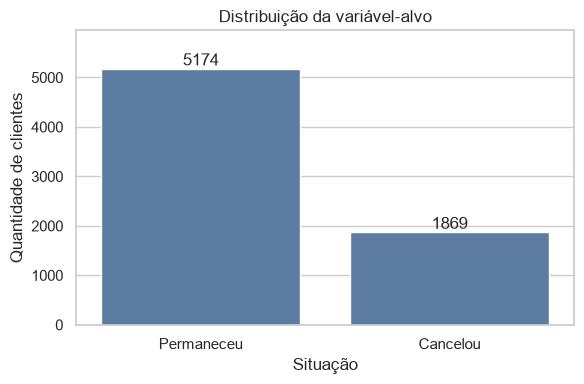

In [6]:
contagem = df["Churn Value"].value_counts().reindex([0, 1], fill_value=0)
taxa_churn = df["Churn Value"].mean()
print(f"Clientes que permaneceram: {contagem.loc[0]:,} ({contagem.loc[0]/len(df):.1%})")
print(f"Clientes que cancelaram: {contagem.loc[1]:,} ({taxa_churn:.1%})")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Permaneceu", "Cancelou"], y=contagem.values, color="#527bad", ax=ax)
ax.set(title="Distribuição da variável-alvo", xlabel="Situação", ylabel="Quantidade de clientes")
for i, qtd in enumerate(contagem.values):
    ax.text(i, qtd + len(df)*0.01, str(qtd), ha="center")
ax.set_ylim(0, contagem.max()*1.15)
fig.tight_layout()
fig.savefig(SAIDAS / "01_distribuicao_churn.png", dpi=150)
plt.show()

### 5.1 Tipo de contrato

Aqui comparo a porcentagem de cancelamentos em cada contrato. Olhar só a quantidade de cancelamentos poderia confundir, porque alguns tipos de contrato tem muito mais clientes que outros.

,taxa_churn,clientes
Contract,,
Month-to-month,42.7%,3875
One year,11.3%,1473
Two year,2.8%,1695


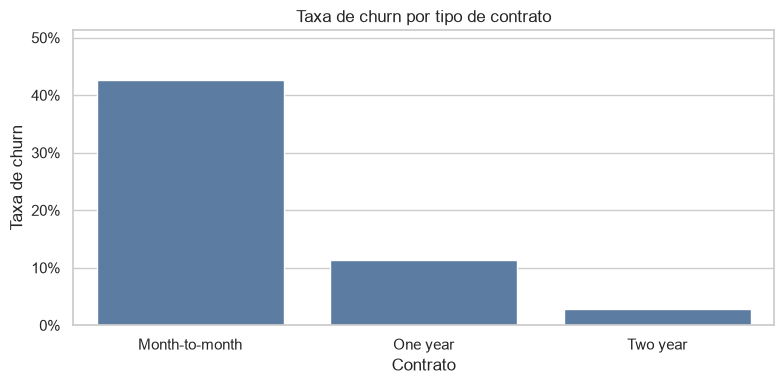

In [7]:
taxa_contrato = df.groupby("Contract", dropna=False)["Churn Value"].agg(["mean", "count"]).sort_values("mean", ascending=False)
display(taxa_contrato.rename(columns={"mean": "taxa_churn", "count": "clientes"}).style.format({"taxa_churn": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=taxa_contrato.index.astype(str), y=taxa_contrato["mean"].values, color="#527bad", ax=ax)
ax.set(title="Taxa de churn por tipo de contrato", xlabel="Contrato", ylabel="Taxa de churn", ylim=(0, max(0.5, taxa_contrato['mean'].max()*1.2)))
ax.yaxis.set_major_formatter(__import__('matplotlib').ticker.PercentFormatter(1.0))
fig.tight_layout()
fig.savefig(SAIDAS / "02_churn_por_contrato.png", dpi=150)
plt.show()

### 5.2 Tempo como cliente e valores cobrados

Quero verificar se o tempo de relacionamento e a cobrança mensal são diferentes entre os clientes que permaneceram e os que cancelaram. Para isso, uso um histograma, as medianas e um boxplot.

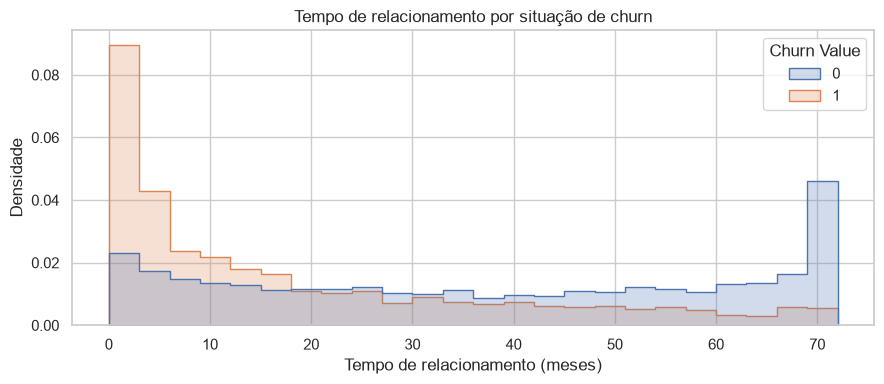

,Tenure Months,Monthly Charges,Total Charges
Churn Value,,,
Permaneceu,38.0,64.425,1679.525
Cancelou,10.0,79.650,703.550


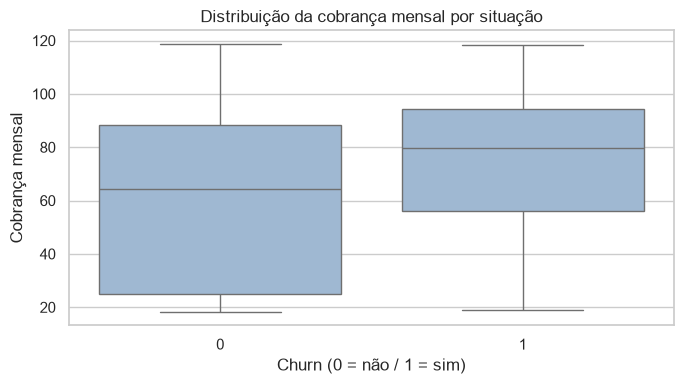

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Tenure Months", hue="Churn Value", bins=24, stat="density", common_norm=False, element="step", ax=ax)
ax.set(title="Tempo de relacionamento por situação de churn", xlabel="Tempo de relacionamento (meses)", ylabel="Densidade")
fig.tight_layout()
fig.savefig(SAIDAS / "03_tenure_por_churn.png", dpi=150)
plt.show()

display(df.groupby("Churn Value")[["Tenure Months", "Monthly Charges", "Total Charges"]].median().rename(index={0:"Permaneceu",1:"Cancelou"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="Churn Value", y="Monthly Charges", order=[0,1], color="#97b8da", ax=ax)
ax.set(title="Distribuição da cobrança mensal por situação", xlabel="Churn (0 = não / 1 = sim)", ylabel="Cobrança mensal")
fig.tight_layout()
fig.savefig(SAIDAS / "04_cobranca_por_churn.png", dpi=150)
plt.show()

### 5.3 Internet e a forma de pagamento

Também comparo as taxas de churn por tipo de internet e por forma de pagamento. Essas diferenças podem ter relação com outras características, como contrato e tempo de relacionamento.

,Taxa de churn (%) — Internet Service
Internet Service,
Fiber optic,41.89
DSL,18.96
No,7.40


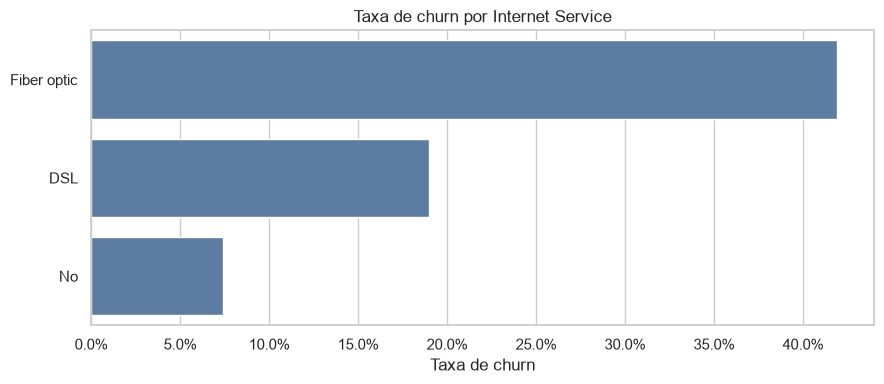

,Taxa de churn (%) — Payment Method
Payment Method,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


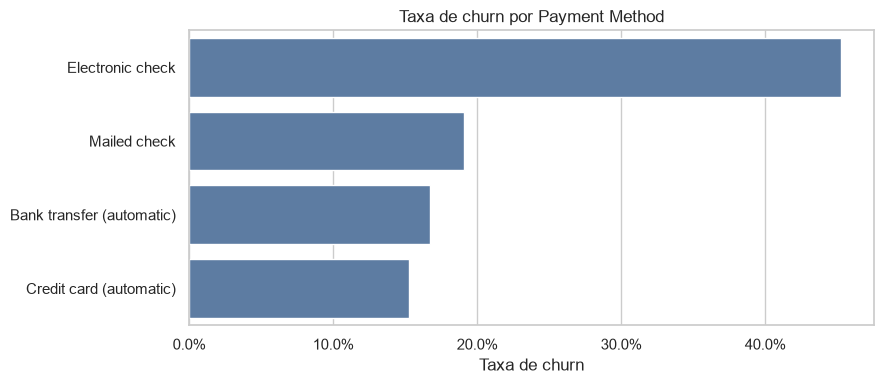

In [9]:
colunas_eda = ["Internet Service", "Payment Method"]
for coluna in colunas_eda:
    taxas = df.groupby(coluna, dropna=False)["Churn Value"].mean().sort_values(ascending=False)
    display((taxas*100).round(2).rename(f"Taxa de churn (%) — {coluna}").to_frame())
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.barplot(x=taxas.values, y=taxas.index.astype(str), color="#527bad", ax=ax, orient="h")
    ax.set(title=f"Taxa de churn por {coluna}", xlabel="Taxa de churn", ylabel="")
    ax.xaxis.set_major_formatter(__import__('matplotlib').ticker.PercentFormatter(1.0))
    fig.tight_layout()
    arquivo = "05_internet.png" if coluna == "Internet Service" else "06_pagamento.png"
    fig.savefig(SAIDAS / arquivo, dpi=150)
    plt.show()

### 5.4 Outros serviços e características

Repito a comparação para alguns serviços e características dos clientes. Além da taxa de churn, mostro a quantidade de clientes por grupo, porque percentuais calculados com poucos registros podem enganar.

In [10]:
for coluna in ["Partner", "Dependents", "Paperless Billing", "Online Security", "Tech Support"]:
    analise = (df.groupby(coluna, dropna=False)["Churn Value"]
                  .agg(clientes="size", cancelamentos="sum", taxa_churn="mean")
                  .sort_values("taxa_churn", ascending=False))
    print(f"\n{coluna}")
    display(analise.style.format({"taxa_churn": "{:.1%}"}))

print("\nDistribuição numérica geral (intervalos e quartis):")
display(df[["Tenure Months", "Monthly Charges", "Total Charges"]].describe().T.round(2))


Partner


,clientes,cancelamentos,taxa_churn
Partner,,,
No,3641,1200,33.0%
Yes,3402,669,19.7%



Dependents


,clientes,cancelamentos,taxa_churn
Dependents,,,
No,5416,1763,32.6%
Yes,1627,106,6.5%



Paperless Billing


...

,clientes,cancelamentos,taxa_churn
Online Security,,,
No,3498,1461,41.8%
Yes,2019,295,14.6%
No internet service,1526,113,7.4%



Tech Support


,clientes,cancelamentos,taxa_churn
Tech Support,,,
No,3473,1446,41.6%
Yes,2044,310,15.2%
No internet service,1526,113,7.4%



Distribuição numérica geral (intervalos e quartis):


,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
Monthly Charges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
Total Charges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


### 5.4.1 Demais variáveis categóricas

Para cobrir todas as variáveis que podem entrar nos modelos, repito a comparação para as colunas restantes. `Gender` e `Senior Citizen` ficam fora do baseline desta etapa, mas entram no modelo da Etapa 2. Por isso, também olho a distribuição delas aqui.


In [ ]:
# Mesma análise da seção anterior, para as colunas que ainda não foram vistas.
for coluna in ["Gender", "Senior Citizen", "Phone Service", "Multiple Lines",
               "Online Backup", "Device Protection", "Streaming TV", "Streaming Movies"]:
    analise = (df.groupby(coluna, dropna=False)["Churn Value"]
                  .agg(clientes="size", cancelamentos="sum", taxa_churn="mean")
                  .sort_values("taxa_churn", ascending=False))
    analise["taxa_churn"] = (analise["taxa_churn"] * 100).round(1)
    print(f"\n{coluna}")
    print(analise.to_string())



Gender
        clientes  cancelamentos  taxa_churn
Gender                                     
Female      3488            939        26.9
Male        3555            930        26.2

Senior Citizen
                clientes  cancelamentos  taxa_churn
Senior Citizen                                     
Yes                 1142            476        41.7
No                  5901           1393        23.6

Phone Service
               clientes  cancelamentos  taxa_churn
Phone Service                                     
Yes                6361           1699        26.7
No                  682            170        24.9

Multiple Lines
                  clientes  cancelamentos  taxa_churn
Multiple Lines                                       
Yes                   2971            850        28.6
No                    3390            849        25.0
No phone service       682            170        24.9

Online Backup
                     clientes  cancelamentos  taxa_churn
Online Backup  

Quase não há diferença entre `Female` (26,9%) e `Male` (26,2%), nem entre ter ou não telefone. Já os clientes com `Senior Citizen` têm taxa bem maior (41,7% contra 23,6%), o que torna esse grupo importante na análise de possíveis vieses. Entre quem tem internet, não ter `Online Backup` ou `Device Protection` aparece junto de churn maior; os serviços de streaming mostram diferença pequena. São associações, não causas.


### 5.5 Correlação entre os campos numéricos

A matriz de correlação ajuda a ver quais variáveis numéricas tendem a variar juntas. Ela não explica a causa dessas relações e não substitui a análise das variáveis categóricas.

,Tenure Months,Monthly Charges,Total Charges,Churn Value
Tenure Months,1.00,0.25,0.83,-0.35
Monthly Charges,0.25,1.00,0.65,0.19
Total Charges,0.83,0.65,1.00,-0.20
Churn Value,-0.35,0.19,-0.20,1.00


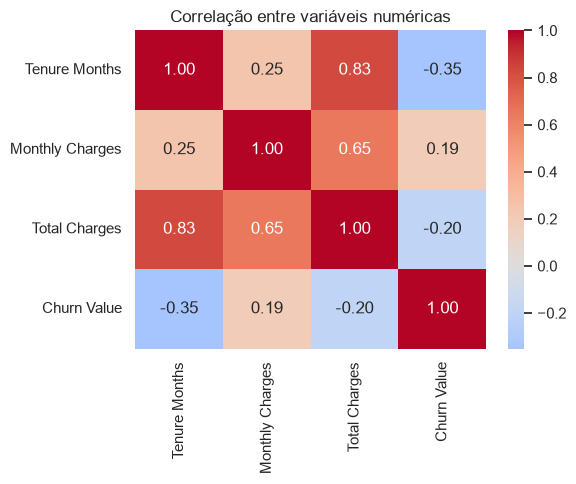

In [11]:
colunas_corr = ["Tenure Months", "Monthly Charges", "Total Charges", "Churn Value"]
matriz_corr = df[colunas_corr].corr()
display(matriz_corr.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Correlação entre variáveis numéricas")
fig.tight_layout()
fig.savefig(SAIDAS / "07_correlacoes.png", dpi=150)
plt.show()

### 5.6 Principais observações

A celula abaixo resume alguns números da EDA usando os valores encontrados no próprio CSV. Vou considerar essas diferenças como indicios para investigar e não como explicações definitivas para o churn.

In [12]:
contrato_maior = taxa_contrato.index[0]
contrato_menor = taxa_contrato.index[-1]
medianas_tenure = df.groupby("Churn Value")["Tenure Months"].median()
pagamento_eda = df.groupby("Payment Method")["Churn Value"].mean().sort_values(ascending=False)
display(Markdown(f"""
- A base contem {len(df):,} clientes e taxa de churn de {taxa_churn:.1%}.
- O contrato {contrato_maior} tem a maior taxa de churn na amostra ({taxa_contrato.loc[contrato_maior, 'mean']:.1%}); {contrato_menor} tem a menor ({taxa_contrato.loc[contrato_menor, 'mean']:.1%}).
- A mediana de tempo de relacionamento é {medianas_tenure.loc[1]:.0f} meses entre clientes que cancelaram e {medianas_tenure.loc[0]:.0f} meses entre os que permaneceram.
- Entre as formas de pagamento, {pagamento_eda.index[0]} tem maior taxa de churn ({pagamento_eda.iloc[0]:.1%}).
- Essas diferenças descrevem o conjunto analisado; não demonstram que uma variável isolada causa cancelamento.
"""))


- A base contem 7,043 clientes e taxa de churn de 26.5%.
- O contrato Month-to-month tem a maior taxa de churn na amostra (42.7%); Two year tem a menor (2.8%).
- A mediana de tempo de relacionamento é 10 meses entre clientes que cancelaram e 38 meses entre os que permaneceram.
- Entre as formas de pagamento, Electronic check tem maior taxa de churn (45.3%).
- Essas diferenças descrevem o conjunto analisado; não demonstram que uma variável isolada causa cancelamento.


## 6. Quais colunas entram no modelo?

Neste primeiro modelo, vou usar informações sobre contratos, serviços, tempo como cliente e cobranças. Deixei de fora as colunas que poderiam entregar a resposta, como Churn Label, Churn Score` e Churn Reason.

Também exclui CLTV, porque não sei exatamente quando essa estimativa foi calculada. Identificadores, localização detalhada e os dados demográficos Gender e Senior Citizen ficaram fora do baseline. Essa é uma escolha para começar com um conjunto de variáveis mais simples; ela pode ser revista na Etapa 2.

O objetivo é usar apenas informações que poderiam estar disponíveis antes de o cliente cancelar.

In [13]:
# Separo as colunas numéricas das categóricas antes de montar o pipeline.
NUMERICAS = ["Tenure Months", "Monthly Charges", "Total Charges"]
CATEGORICAS = [
    "Partner", "Dependents", "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection", "Tech Support",
    "Streaming TV", "Streaming Movies", "Contract", "Paperless Billing", "Payment Method"
]
FEATURES = NUMERICAS + CATEGORICAS
faltantes = [col for col in FEATURES if col not in df.columns]
if faltantes:
    raise ValueError(f"A versão da base não possui as variáveis esperadas: {faltantes}")

X = df[FEATURES].copy()
y = df["Churn Value"].astype(int)

excluidas = sorted(set(df.columns) - set(FEATURES) - {"Churn Value"})
print("Variaveis selecionadas:", len(FEATURES))
print("Variaveis não utilizadas no modelo:", excluidas)
print("Dimensões de X:", X.shape, "| Proporção de churn:", f"{y.mean():.1%}")

Variaveis selecionadas: 17
Variaveis não utilizadas no modelo: ['CLTV', 'Churn Label', 'Churn Reason', 'Churn Score', 'City', 'Count', 'Country', 'CustomerID', 'Gender', 'Lat Long', 'Latitude', 'Longitude', 'Senior Citizen', 'State', 'Zip Code']
Dimensões de X: (7043, 17) | Proporção de churn: 26.5%


## 7. Separação entre treino e teste

Separei 80% dos clientes para treinar o modelo e 20% para testar. Usei stratify=y para manter aproximadamente a mesma proporção de cancelamentos nos dois grupos.

A semente é 123. Também tomei o cuidado de deixar o cálculo de medianas, modas e escalas para depois da divisão, dentro do pipeline de treinamento.

In [14]:
# Uso a mesma divisão para comparar este modelo com os próximos.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)
print("Treino:", X_treino.shape, "| churn:", f"{y_treino.mean():.1%}")
print("Teste:", X_teste.shape, "| churn:", f"{y_teste.mean():.1%}")

Treino: (5634, 17) | churn: 26.5%
Teste: (1409, 17) | churn: 26.5%


## 8. Preparando os dados e treinando a Regressão Logística

A Regressão Logística precisa receber números. Por isso, apliquei os seguintes tratamentos:

- **Colunas numéricas:** preencho eventuais ausências com a mediana e depois padronizo os valores.
- **Colunas categóricas:** preencho eventuais ausências com a categoria mais comum e converto as categorias em colunas numéricas com OneHotEncoder.

Coloquei tudo em um 'Pipeline' para aplicar o mesmo tratamento no treino e no teste, sem usar os dados de teste para aprender esses ajustes.

Como há mais clientes que permaneceram do que clientes que cancelaram, usei class_weight="balanced". Mantive o limite padrão de 0,50 para classificar o cancelamento. Nesta etapa, a intenção é ter uma primeira referencia, não procurar a melhor configuração possivel.

In [15]:
# As transformações ficam dentro do pipeline para serem ajustadas apenas no treino.
preparo_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escala", StandardScaler())
])
preparo_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessamento = ColumnTransformer(transformers=[
    ("num", preparo_numerico, NUMERICAS),
    ("cat", preparo_categorico, CATEGORICAS)
])

baseline = Pipeline(steps=[
    ("preprocessamento", preprocessamento),
    ("classificador", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMENTE))
])

baseline.fit(X_treino, y_treino)
print("Baseline treinado com sucesso.")

Baseline treinado com sucesso.


## 9. Como avaliar o modelo

Vou observar cinco medidas:
- **Precisão (precision):** entre os clientes classificados como risco de churn, quantos realmente cancelaram?
- **Recall:** de todos os que cancelaram, quantos o modelo conseguiu identificar?
- **F1-score:** combina precisão e recall em uma única medida.
- **ROC-AUC:** mostra a capacidade de separar as duas classes considerando vários limiares.
- **Acurácia:** mostra a proporção total de acertos, mas sozinha pode esconder erros na classe de churn.

Para transformar as probabilidades em previsões de 0 ou 1, uso o limiar de **0,50**, sem ajustá-lo com os resultados do teste.

In [16]:
prob_teste = baseline.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste >= 0.50).astype(int)
metricas = {
    "accuracy": accuracy_score(y_teste, pred_teste),
    "precision": precision_score(y_teste, pred_teste, zero_division=0),
    "recall": recall_score(y_teste, pred_teste, zero_division=0),
    "f1": f1_score(y_teste, pred_teste, zero_division=0),
    "roc_auc": roc_auc_score(y_teste, prob_teste),
    "test_size": len(y_teste),
    "train_size": len(y_treino),
    "threshold": 0.50,
    "random_state": SEMENTE,
    "class_weight": "balanced"
}
print("Métricas da Regressão Logistica:")
display(pd.Series(metricas).to_frame("valor"))
print("Relatório por classe:")
print(classification_report(y_teste, pred_teste, target_names=["Permaneceu", "Cancelou"], zero_division=0))

Métricas da Regressão Logistica:


,valor
accuracy,0.762952
precision,0.535842
recall,0.799465
f1,0.641631
roc_auc,0.852689
test_size,1409
train_size,5634
threshold,0.5
random_state,123
class_weight,balanced


Relatório por classe:
              precision    recall  f1-score   support

  Permaneceu       0.91      0.75      0.82      1035
    Cancelou       0.54      0.80      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



### 9.1 Comparação com uma regra bem simples

Para ter uma referência, comparei o modelo com uma regra que prevê que **todos os clientes vão permanecer**. Como a maioria realmente permanece, essa regra pode ter uma acurácia relativamente alta. Mas ela não encontra nenhum cancelamento, então o recall e o F1 para churn são zero.

In [17]:
pred_maioria = np.zeros(len(y_teste), dtype=int)
print(f"Acurácia prevendo sempre 'permaneceu': {accuracy_score(y_teste, pred_maioria):.3f}")
print(f"Recall para churn da regra ingênua: {recall_score(y_teste, pred_maioria, zero_division=0):.3f}")
print(f"F1 para churn da regra ingênua: {f1_score(y_teste, pred_maioria, zero_division=0):.3f}")
print(f"Regressão Logística — F1: {metricas['f1']:.3f} | ROC-AUC: {metricas['roc_auc']:.3f}")

Acurácia prevendo sempre 'permaneceu': 0.735
Recall para churn da regra ingênua: 0.000
F1 para churn da regra ingênua: 0.000
Regressão Logística — F1: 0.642 | ROC-AUC: 0.853


### 9.2 Matriz de confusão e curva ROC

A matriz de confusão mostra quantos clientes o modelo acertou e onde errou. Para o negócio, dois erros merecem atenção: sinalizar alguém que não cancelaria e deixar de identificar alguém que cancelaria.

A curva ROC ajuda a visualizar como o modelo separa essas duas situações em diferentes limiares.

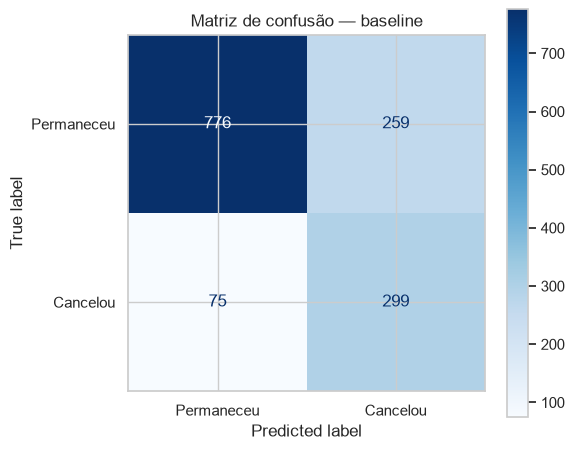

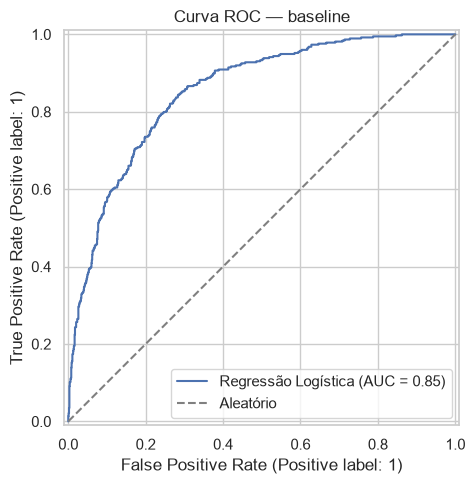

Verdadeiros negativos: 776; falsos positivos: 259; falsos negativos: 75; verdadeiros positivos: 299


In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, pred_teste, display_labels=["Permaneceu", "Cancelou"],
    cmap="Blues", values_format="d", ax=ax
)
ax.set_title("Matriz de confusão — baseline")
fig.tight_layout()
fig.savefig(SAIDAS / "08_matriz_confusao.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_teste, prob_teste, name="Regressão Logística", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
ax.set_title("Curva ROC — baseline")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(SAIDAS / "09_curva_roc.png", dpi=150)
plt.show()

resultado_confusao = confusion_matrix(y_teste, pred_teste)
tn, fp, fn, tp = resultado_confusao.ravel()
print(f"Verdadeiros negativos: {tn}; falsos positivos: {fp}; falsos negativos: {fn}; verdadeiros positivos: {tp}")

## 10. Métrica de negócio: cobrança mensal associada aos cancelamentos identificados

Além das métricas técnicas, quis observar quanto da cobrança mensal dos clientes que **realmente cancelaram** estava associada aos clientes que o modelo conseguiu identificar.

\[
\mathrm{Cobertura} = \frac{\text{Soma da cobrança mensal dos clientes que cancelaram e foram identificados}}{\text{Soma da cobrança mensal de todos os clientes que cancelaram}}
\]

Essa conta é apenas uma forma de enxergar o alcance do modelo sobre a cobrança mensal exposta ao churn. **Não representa dinheiro recuperado**, porque não simulamos nenhuma ação de retenção. Usei `Monthly Charges`, e não `Total Charges`, pois este último representa valores acumulados de cobranças anteriores.

In [19]:
valores = pd.DataFrame({
    "cobranca_mensal": X_teste["Monthly Charges"].values,
    "churn_real": y_teste.values,
    "churn_previsto": pred_teste
})

receita_churn = valores.loc[valores["churn_real"].eq(1), "cobranca_mensal"].sum()
receita_identificada = valores.loc[
    valores["churn_real"].eq(1) & valores["churn_previsto"].eq(1), "cobranca_mensal"
].sum()
cobertura_receita = receita_identificada / receita_churn if receita_churn > 0 else np.nan
clientes_sinalizados = int(pred_teste.sum())

metricas["cobertura_receita_churn"] = float(cobertura_receita)
metricas["clientes_sinalizados"] = clientes_sinalizados

print(f"Cobrança mensal dos churners no teste: {receita_churn:,.2f} (unidades monetárias originais da base)")
print(f"Cobrança mensal de churners identificados: {receita_identificada:,.2f}")
print(f"Cobertura de receita associada ao churn: {cobertura_receita:.1%}")
print(f"Clientes sinalizados para contato no teste: {clientes_sinalizados}")
print("Atenção: não é uma estimativa de receita efetivamente recuperada.")

Cobrança mensal dos churners no teste: 27,671.25 (unidades monetárias originais da base)
Cobrança mensal de churners identificados: 22,907.10
Cobertura de receita associada ao churn: 82.8%
Clientes sinalizados para contato no teste: 558
Atenção: não é uma estimativa de receita efetivamente recuperada.


## 11. Arquivos para a próxima etapa

Salvei as métricas e as configurações usadas no baseline, além do próprio modelo. Isso facilita o trabalho de quem vai treinar Random Forest e MLP: todos podem usar a mesma separação dos dados e comparar os resultados de forma justa.

Este ainda é só o **modelo inicial**, não o modelo escolhido para uso final.

In [20]:
# Guardo o modelo e as configurações para facilitar a comparação na Etapa 2.
import joblib

arquivo_metricas = MODELOS / "baseline_metricas.json"
with open(arquivo_metricas, "w", encoding="utf-8") as arquivo:
    json.dump(metricas, arquivo, indent=2, ensure_ascii=False)

configuracao = {
    "seed": SEMENTE,
    "test_size": 0.20,
    "estratificacao": True,
    "limiar": 0.50,
    "features": FEATURES,
    "numericas": NUMERICAS,
    "categoricas": CATEGORICAS,
    "modelo": "Regressão Logística",
    "fonte": origem
}
with open(MODELOS / "baseline_configuracao.json", "w", encoding="utf-8") as arquivo:
    json.dump(configuracao, arquivo, indent=2, ensure_ascii=False)

joblib.dump(baseline, MODELOS / "baseline_logistica.joblib")
print("Resultados do baseline exportados para:", MODELOS)

Resultados do baseline exportados para: c:\Users\Home\Documents\tech_challenge_fase_1\models


## 12. Conclusões

Nesta etapa, conferi a qualidade da base, tratei os campos de cobrança que estavam vazios, analisei a distribuição dos cancelamentos e treinei uma Regressão Logística como primeiro modelo.

A análise mostrou diferenças entre grupos de clientes, especialmente por tipo de contrato e tempo de relacionamento. Essas observações ajudam a entender os dados, mas não são suficientes para dizer que esses fatores, sozinhos, causam o cancelamento.

O desempenho do modelo aparece nas métricas e nos gráficos acima. A Regressão Logística servirá como referência para comparar os modelos da Etapa 2.

**Limitações:** a base representa um conjunto de clientes em um determinado período, sem um histórico mensal completo para simular previsões ao longo do tempo. Também não dá para afirmar quanto a empresa conseguiria reter apenas com as previsões. Antes de usar um modelo assim na prática, seria necessário validá-lo com dados mais recentes e acompanhar possíveis erros e vieses.

**Para continuar o trabalho:** usar a mesma divisão 80/20, a semente **123** e as mesmas variáveis. Na Etapa 2, os novos modelos podem ser comparados por F1, ROC-AUC, precisão e recall, sem escolher parâmetros com base no conjunto de teste.

In [21]:
display(Markdown(f"""
### Resumo do modelo inicial

A Regressão Logística teve **F1 = {metricas['f1']:.3f}**, **ROC-AUC = {metricas['roc_auc']:.3f}** e **recall = {metricas['recall']:.3f}** na amostra de teste.
A cobertura de cobrança mensal dos clientes com churn foi de **{metricas['cobertura_receita_churn']:.1%}**, com **{metricas['clientes_sinalizados']} clientes sinalizados** em {len(y_teste)} registros de teste.

*Esses resultados mostram o desempenho neste conjunto de teste. Eles não representam receita recuperada nem uma taxa real de retenção.*
"""))


### Resumo do modelo inicial

A Regressão Logística teve **F1 = 0.642**, **ROC-AUC = 0.853** e **recall = 0.799** na amostra de teste.
A cobertura de cobrança mensal dos clientes com churn foi de **82.8%**, com **558 clientes sinalizados** em 1409 registros de teste.

*Esses resultados mostram o desempenho neste conjunto de teste. Eles não representam receita recuperada nem uma taxa real de retenção.*
